# Aula 2 — dados e métricas do NYC Taxi

Fontes de conteúdo: slides da Aula 22, itens 9 e 13–17, e enunciado.
Público proposto: equipe de planejamento operacional.

O aluno solicitou usar um CSV de 200.000 viagens da Silver tratada. A seleção
da amostra é documentada no código abaixo. Não são adicionadas regras de limpeza.
Os resultados não representam contagens da Silver completa nem toda a cidade.

Execute a partir de `notebooks/`. A primeira célula gera o CSV se ele não existir.
Os Parquets da Aula 1 são as entradas versionadas da geração.

Seleção aprovada: amostra aleatória sem reposição, 200.000 viagens, `seed=42`,
seguindo a abordagem Polars usada na EDA.


In [1]:
from pathlib import Path
import pandas as pd
import polars as pl
import matplotlib.pyplot as plt

csv_path = Path('../data/clean/dataset.csv')
if not csv_path.exists():
    silver = pl.scan_parquet('../data/clean/dataset.parquet/part-*.parquet').collect(engine='streaming')
    amostra = silver.sample(n=200_000, seed=42)
    amostra.to_pandas().to_csv(csv_path, index=False)
    del silver, amostra
quantitativas = [
    'trip_distance', 'fare_amount', 'trip_duration_minutes', 'tip_amount', 'total_amount'
]
dados = pd.read_csv(csv_path, usecols=quantitativas + ['pickup_datetime'], parse_dates=['pickup_datetime'])
assert len(dados) == 200_000
print('Viagens da amostra:', len(dados))


Viagens da amostra: 200000


## Mesmo filtro do app

O intervalo inclusivo de distância, em milhas, afeta as duas abas. Os limites
iniciais preservam toda a amostra; altere-os para testar outro recorte.
A seleção de variáveis do Dashboard 1 não altera os KPIs.


In [2]:
distancia_minima = dados['trip_distance'].min()
distancia_maxima = dados['trip_distance'].max()
df = dados.loc[dados['trip_distance'].between(distancia_minima, distancia_maxima)]
print('Intervalo:', distancia_minima, distancia_maxima)
print('Viagens no recorte:', len(df))


Intervalo: 0.01 125.97
Viagens no recorte: 200000


## Quatro métricas em pandas

Contagem de viagens e médias diretamente nas linhas do recorte. As médias
ignoram nulos de cada variável. Total cobrado não representa lucro.


In [3]:
viagens = len(df)
distancia_media = df['trip_distance'].mean()
duracao_media = df['trip_duration_minutes'].mean()
valor_medio = df['total_amount'].mean()

resultado = pd.DataFrame({
    'Métrica': ['Viagens avaliadas', 'Distância média (milhas)', 'Duração média (min)', 'Total médio cobrado (USD)'],
    'Valor': [viagens, distancia_media, duracao_media, valor_medio],
})
resultado


,Métrica,Valor
0,Viagens avaliadas,200000.000000
1,Distância média (milhas),9.094031
2,Duração média (min),33.125510
3,Total médio cobrado (USD),40.524035


## Correspondência com o app

```python
st.metric("Viagens avaliadas", f"{viagens:,}")
st.metric("Distância média (milhas)", "—" if pd.isna(distancia_media) else f"{distancia_media:.2f}")
st.metric("Duração média (min)", "—" if pd.isna(duracao_media) else f"{duracao_media:.2f}")
st.metric("Total médio cobrado (USD)", "—" if pd.isna(valor_medio) else f"{valor_medio:.2f}")
```


## Visual prévio — viagens por hora de embarque

A hora é derivada de `pickup_datetime`, no horário registrado na fonte.
O gráfico descreve viagens registradas, não demanda não atendida.


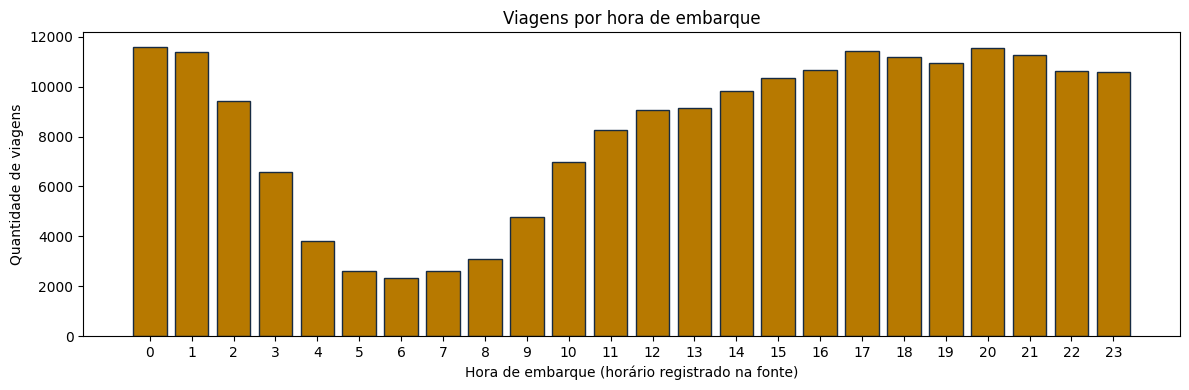

In [4]:
por_hora = (
    df.groupby(df['pickup_datetime'].dt.hour)
    .size()
    .reindex(range(24), fill_value=0)
)
assert por_hora.sum() == df['pickup_datetime'].notna().sum()
fig, ax = plt.subplots(figsize=(12, 4))
ax.bar(por_hora.index, por_hora.values, color='#B77900', edgecolor='#172B43')
ax.set_title('Viagens por hora de embarque')
ax.set_xlabel('Hora de embarque (horário registrado na fonte)')
ax.set_ylabel('Quantidade de viagens')
ax.set_xticks(range(24))
fig.tight_layout()
plt.show()
